In [1]:

# Cell 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)


In [2]:

# Cell 2: Load dataset

df = pd.read_csv("../data/raw/online_retail.csv")

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [3]:

# Cell 3: Check data quality

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 69.3 MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records:
5268

Statistical Summary:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,"541,909.00",541909,"541,909.00","406,829.00",541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2011-10-31 14:41:00,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.55,NaN,4.61,"15,287.69",NaN
std,NaN,NaN,NaN,218.08,NaN,96.76,"1,713.60",NaN
min,NaN,NaN,NaN,"-80,995.00",NaN,"-11,062.06","12,346.00",NaN
25%,NaN,NaN,NaN,1.00,NaN,1.25,"13,953.00",NaN
50%,NaN,NaN,NaN,3.00,NaN,2.08,"15,152.00",NaN
75%,NaN,NaN,NaN,10.00,NaN,4.13,"16,791.00",NaN


In [4]:

# Cell 4: Remove exact duplicate records

df = df.drop_duplicates().copy()

# Convert InvoiceDate into datetime format
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Remove rows with invalid dates
df = df.dropna(subset=["InvoiceDate"])

print("Shape after duplicate removal:", df.shape)


Shape after duplicate removal: (536641, 8)


In [5]:

# Cell 5: Separate cancellation transactions

cancellations = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep normal invoices for sales analysis
sales = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Cancellation Records:", len(cancellations))
print("Normal Invoice Records:", len(sales))


Cancellation Records: 9251
Normal Invoice Records: 527390


In [6]:

# Cell 6: Filter valid sales records

sales = sales[
    (sales["Quantity"] > 0) &
    (sales["UnitPrice"] > 0)
].copy()

# Calculate revenue
sales["Revenue"] = (
    sales["Quantity"] * sales["UnitPrice"]
)

# Extract date components
sales["Year"] = sales["InvoiceDate"].dt.year
sales["Month"] = sales["InvoiceDate"].dt.month

sales["YearMonth"] = (
    sales["InvoiceDate"].dt.to_period("M").astype(str)
)

print("Cleaned Sales Shape:", sales.shape)
display(sales.head())


Cleaned Sales Shape: (524878, 12)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,15.30,2010,12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010,12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,22.00,2010,12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010,12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010,12,2010-12


In [7]:

# Cell 7: Export cleaned datasets

sales.to_csv(
    "../data/processed/cleaned_sales.csv",
    index=False
)

cancellations.to_csv(
    "../data/processed/cancellation_records.csv",
    index=False
)

print("Cleaned datasets exported successfully!")


Cleaned datasets exported successfully!


In [8]:
# Check duplicates before removal
print("Duplicates before:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates().copy()

print("Duplicates after:", df.duplicated().sum())
print("Updated shape:", df.shape)

Duplicates before: 0
Duplicates after: 0
Updated shape: (536641, 8)


In [9]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Remove invalid dates
df = df.dropna(subset=["InvoiceDate"]).copy()

print(df["InvoiceDate"].dtype)

datetime64[us]


In [10]:
# Identify cancelled transactions
cancellations = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep normal invoices
sales = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Cancellation records:", len(cancellations))
print("Normal invoice records:", len(sales))

Cancellation records: 9251
Normal invoice records: 527390


In [11]:
print("Negative Quantity:", (sales["Quantity"] < 0).sum())
print("Zero Quantity:", (sales["Quantity"] == 0).sum())

print("Negative UnitPrice:", (sales["UnitPrice"] < 0).sum())
print("Zero UnitPrice:", (sales["UnitPrice"] == 0).sum())

Negative Quantity: 1336
Zero Quantity: 0
Negative UnitPrice: 2
Zero UnitPrice: 2510


In [12]:
sales = sales[
    (sales["Quantity"] > 0) &
    (sales["UnitPrice"] > 0)
].copy()

print("Valid sales records:", sales.shape)

Valid sales records: (524878, 8)


In [13]:
sales["Revenue"] = (
    sales["Quantity"] * sales["UnitPrice"]
)

display(
    sales[[
        "InvoiceNo",
        "Description",
        "Quantity",
        "UnitPrice",
        "Revenue"
    ]].head(10)
)

,InvoiceNo,Description,Quantity,UnitPrice,Revenue
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,WHITE METAL LANTERN,6,3.39,20.34
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34
5,536365,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50
7,536366,HAND WARMER UNION JACK,6,1.85,11.10
8,536366,HAND WARMER RED POLKA DOT,6,1.85,11.10
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08


In [14]:
sales["Year"] = sales["InvoiceDate"].dt.year

sales["Month"] = sales["InvoiceDate"].dt.month

sales["YearMonth"] = (
    sales["InvoiceDate"].dt.to_period("M").astype(str)
)

display(sales.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,15.30,2010,12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010,12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,22.00,2010,12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010,12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010,12,2010-12


In [15]:
sales.to_csv(
    "../data/processed/cleaned_sales.csv",
    index=False
)

cancellations.to_csv(
    "../data/processed/cancellation_records.csv",
    index=False
)

print("Both datasets exported successfully!")

Both datasets exported successfully!


In [16]:
# Overall Business KPIs

total_revenue = sales["Revenue"].sum()

total_orders = sales["InvoiceNo"].nunique()

total_customers = sales["CustomerID"].nunique()

total_products = sales["StockCode"].nunique()

total_units = sales["Quantity"].sum()

average_order_value = total_revenue / total_orders

print("TOTAL REVENUE:", round(total_revenue, 2))
print("TOTAL ORDERS:", total_orders)
print("TOTAL CUSTOMERS:", total_customers)
print("TOTAL PRODUCTS:", total_products)
print("TOTAL UNITS SOLD:", total_units)
print("AVERAGE ORDER VALUE:", round(average_order_value, 2))

TOTAL REVENUE: 10642110.8
TOTAL ORDERS: 19960
TOTAL CUSTOMERS: 4338
TOTAL PRODUCTS: 3922
TOTAL UNITS SOLD: 5572420
AVERAGE ORDER VALUE: 533.17


In [17]:
monthly_sales = sales.groupby("YearMonth").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique")
).reset_index()

monthly_sales["Growth_Percentage"] = (
    monthly_sales["Revenue"].pct_change() * 100
)

display(monthly_sales)

,YearMonth,Revenue,Orders,Growth_Percentage
0,2010-12,"821,452.73",1559,NaN
1,2011-01,"689,811.61",1086,-16.03
2,2011-02,"522,545.56",1100,-24.25
3,2011-03,"716,215.26",1454,37.06
4,2011-04,"536,968.49",1246,-25.03
5,2011-05,"769,296.61",1681,43.27
6,2011-06,"760,547.01",1533,-1.14
7,2011-07,"718,076.12",1475,-5.58
8,2011-08,"757,841.38",1361,5.54
9,2011-09,"1,056,435.19",1837,39.40


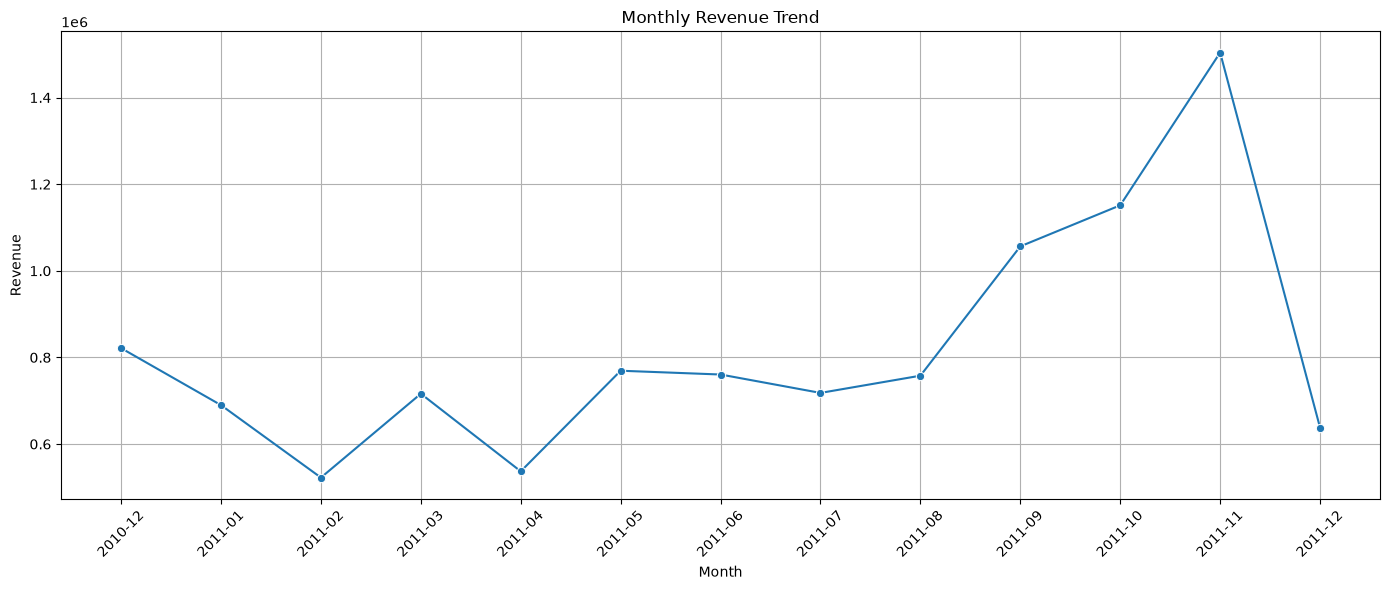

In [18]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [19]:
top_products = (
    sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_products)

,Description,Revenue
0,DOTCOM POSTAGE,"206,248.77"
1,REGENCY CAKESTAND 3 TIER,"174,156.54"
2,"PAPER CRAFT , LITTLE BIRDIE","168,469.60"
3,WHITE HANGING HEART T-LIGHT HOLDER,"106,236.72"
4,PARTY BUNTING,"99,445.23"
5,JUMBO BAG RED RETROSPOT,"94,159.81"
6,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92"
7,POSTAGE,"78,101.88"
8,Manual,"77,752.82"
9,RABBIT NIGHT LIGHT,"66,870.03"


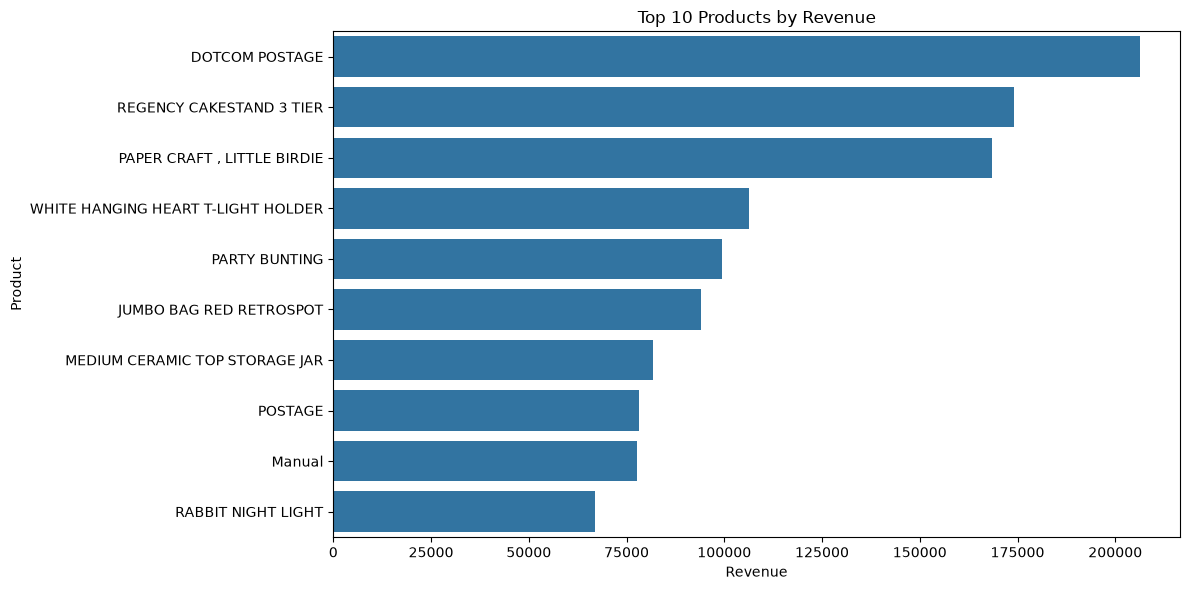

In [20]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="Revenue",
    y="Description"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [21]:
country_sales = (
    sales.groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Customers=("CustomerID", "nunique")
    )
    .sort_values("Revenue", ascending=False)
    .reset_index()
)

display(country_sales.head(15))

,Country,Revenue,Orders,Customers
0,United Kingdom,"9,001,744.09",18019,3920
1,Netherlands,"285,446.34",94,9
2,EIRE,"283,140.52",288,3
3,Germany,"228,678.40",457,94
4,France,"209,625.37",392,87
5,Australia,"138,453.81",57,9
6,Spain,"61,558.56",90,30
7,Switzerland,"57,067.60",54,21
8,Belgium,"41,196.34",98,25
9,Sweden,"38,367.83",36,8


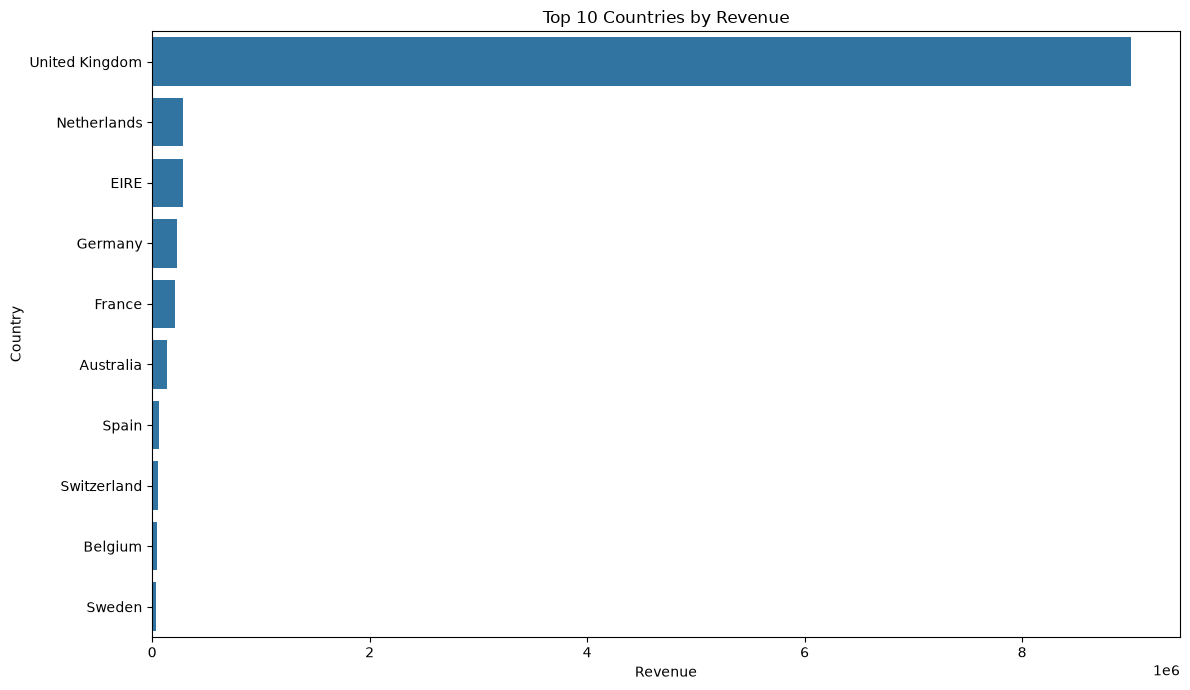

In [22]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=country_sales.head(10),
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.tight_layout()
plt.show()

In [23]:
top_quantity = (
    sales.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_quantity)

,Description,Quantity
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,JUMBO BAG RED RETROSPOT,48371
4,WHITE HANGING HEART T-LIGHT HOLDER,37872
5,POPCORN HOLDER,36749
6,PACK OF 72 RETROSPOT CAKE CASES,36396
7,ASSORTED COLOUR BIRD ORNAMENT,36362
8,RABBIT NIGHT LIGHT,30739
9,MINI PAINT SET VINTAGE,26633


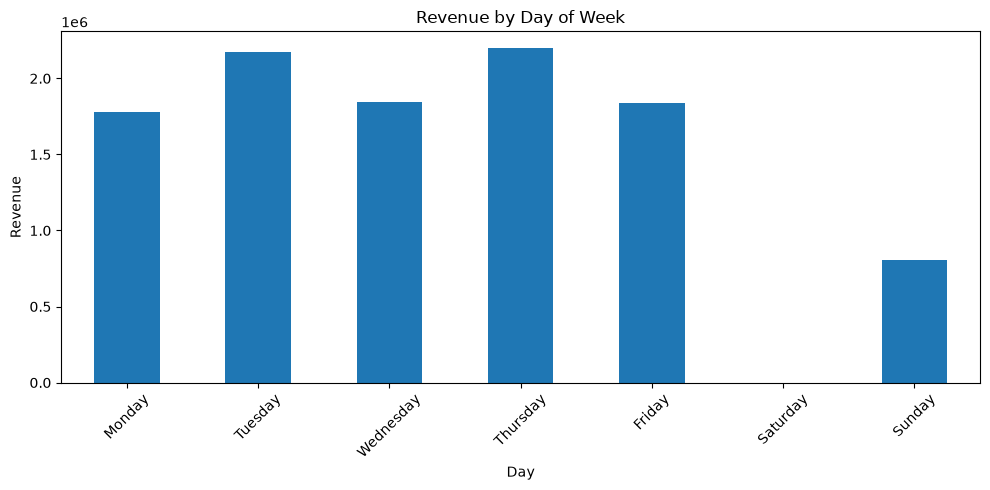

In [24]:
sales["Day"] = sales["InvoiceDate"].dt.day_name()

day_sales = (
    sales.groupby("Day")["Revenue"]
    .sum()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

plt.figure(figsize=(10, 5))
day_sales.plot(kind="bar")

plt.title("Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
import os

os.makedirs("../reports", exist_ok=True)

In [30]:
monthly_sales.to_csv(
    "../reports/monthly_sales_analysis.csv",
    index=False
)

top_products.to_csv(
    "../reports/top_products.csv",
    index=False
)

country_sales.to_csv(
    "../reports/country_sales.csv",
    index=False
)

top_quantity.to_csv(
    "../reports/top_quantity_products.csv",
    index=False
)

print("EDA reports exported successfully!")

EDA reports exported successfully!
